# Nhiệm Vụ 2: Trò Chơi Đấu Tăng — Thực Nghiệm Tìm Kiếm Đối Kháng

Sổ tay thực nghiệm đầy đủ 3 tiểu mục theo yêu cầu đồ án môn **503043 – Nhập môn Trí tuệ Nhân tạo**:
1. **Yêu cầu 2.1:** Kiểm chứng mô hình Trò chơi Tổng bằng không (Zero-Sum Game), thông số sinh lực (`Tank=6`, `Base=9`, `Wall=3`, sát thương `1`) và vật lý đạn bay `3` ô/chu kỳ xử lý từng ô một.
2. **Yêu cầu 2.2:** Đối sánh công bằng **4 cấu hình** (`Minimax thuần`, `Alpha-Beta thuần`, `Heuristic Minimax`, `Heuristic Alpha-Beta`) trên Tầng 1 (Tàn cuộc `7×7`) và đối sánh mở rộng trên Tầng 2 (`9×9` & `11×11`, độ sâu $d \in \{2, 3, 4\}$).
3. **Yêu cầu 2.3:** Kiểm chứng cơ chế nạp động bot nhóm ngoài (`OOP` & `Dict Adapter`), cách ly trạng thái bất biến và giải đấu đối kháng đầy máu.

In [1]:
# Thiet lap moi truong, font tieng Viet cho Matplotlib va bang mau toi gian 3 tong
import sys
from pathlib import Path
from statistics import mean, median

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.edgecolor'] = '#D1D5DB'
plt.rcParams['axes.linewidth'] = 0.9

COLOR_PRIMARY = '#0F766E'
COLOR_ALERT = '#C83E37'
COLOR_INK = '#111827'
COLOR_MUTED = '#6B7280'

current = Path.cwd().resolve()
for candidate in (current, *current.parents):
    if (candidate / 'task2' / 'config.py').exists():
        source_dir = candidate
        break
    if (candidate / 'source' / 'task2' / 'config.py').exists():
        source_dir = candidate / 'source'
        break
else:
    raise RuntimeError('Khong tim thay thu muc source/task2')

if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from task2.agents import (
    AlphaBetaAgent,
    HeuristicAlphaBetaAgent,
    HeuristicMinimaxAgent,
    MinimaxAgent,
    TacticalEvaluator,
    discover_external_agents,
)
from task2.config import ACTION_LABELS_VI, DIR_RIGHT, FIRE, PLAYER_MAX, PLAYER_MIN
from task2.engine import (
    Base,
    BrickWall,
    GameState,
    Tank,
    TankBattleEngine,
    get_all_scenarios,
    get_scenario,
)

figure_dir = source_dir.parent / 'report' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
print('Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 2 thành công.')

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 2 thành công.


## Phần 1 (Yêu cầu 2.1): Kiểm Chứng Mô Hình Zero-Sum Game & Vật Lý Đạn 3 Ô Từng Bước

Xác minh các bất biến cốt lõi: sinh lực ban đầu (`Tank=6`, `Base=9`, `Wall=3`), đạn bay từng ô một dừng ngay khi chạm chướng ngại vật đầu tiên, trạng thái `GameState` bất biến và tính phản đối xứng của hàm lượng giá `EVAL(s, MAX) == -EVAL(s, MIN)`.

In [2]:
# Kiem chung vat ly dan bay 3 o dung tai tuong gach va tinh bat bien trang thai
s_test = GameState(
    rows=5, cols=7,
    tanks={PLAYER_MAX: Tank(PLAYER_MAX, 2, 1, facing=DIR_RIGHT), PLAYER_MIN: Tank(PLAYER_MIN, 2, 4, facing='LEFT')},
    bases={PLAYER_MAX: Base(PLAYER_MAX, 4, 0), PLAYER_MIN: Base(PLAYER_MIN, 0, 6)},
    brick_walls={(2, 3): BrickWall(2, 3)},
    current_player=PLAYER_MAX,
)
s_next, ev = TankBattleEngine.step_with_events(s_test, FIRE)
assert s_next.brick_walls[(2, 3)].hp == 2
assert s_next.tanks[PLAYER_MIN].hp == 6 and len(s_next.bullets) == 0

for key in ('classic_9x9', 'crossfire_9x9', 'fortress_11x11'):
    st0 = get_scenario(key).builder()
    assert abs(TacticalEvaluator.evaluate(st0, PLAYER_MAX) + TacticalEvaluator.evaluate(st0, PLAYER_MIN)) < 1e-6

print('Kiểm chứng vật lý đạn 3 ô/chu kỳ:', ev.impacts, '-> Tường gạch còn HP =', s_next.brick_walls[(2, 3)].hp)
print('Kiểm chứng phản đối xứng EVAL(s, MAX) + EVAL(s, MIN) = 0: ĐẠT 100%.')

Kiểm chứng vật lý đạn 3 ô/chu kỳ: [(2, 3, 'WALL')] -> Tường gạch còn HP = 2
Kiểm chứng phản đối xứng EVAL(s, MAX) + EVAL(s, MIN) = 0: ĐẠT 100%.


## Phần 2 (Yêu cầu 2.2 — Tầng 1): Đối Sánh Công Bằng 4 Cấu Hình Trên Kịch Bản Tàn Cuộc (`7×7`)

Tất cả 4 cấu hình chạy trên đúng cùng trạng thái khởi đầu của 3 thế cờ tàn cuộc (đo trung vị 3 lần chạy sau warm-up). `Minimax thuần` và `Alpha-Beta thuần` được kiểm chứng cho ra **đúng cùng giá trị và nước đi tối ưu**.

In [3]:
# Khoi dong nhe va chay doi sanh 4 cau hinh tren 3 kich ban Tang 1 (trung vi 3 lan)
HeuristicAlphaBetaAgent(max_depth=3).safe_choose_action(get_scenario('endgame_duel_7x7').builder())

tier1_rows = []
repeats = 3
for scen in get_all_scenarios(tier='tier1'):
    s0 = scen.builder()
    configs = [
        MinimaxAgent(max_ply_cap=6, name='Minimax thuần'),
        AlphaBetaAgent(max_ply_cap=6, name='Alpha-Beta thuần'),
        HeuristicMinimaxAgent(max_depth=4, name='Heuristic Minimax'),
        HeuristicAlphaBetaAgent(max_depth=4, name='Heuristic Alpha-Beta'),
    ]
    values_check = {}
    for agent in configs:
        times = []
        act = 'STAY'
        for _ in range(repeats):
            act = agent.safe_choose_action(s0)
            times.append(agent.last_metrics.elapsed_ms)
        m = agent.last_metrics
        values_check[agent.name] = (act, m.best_value)
        tier1_rows.append({
            'Kịch bản': scen.title,
            'Cấu hình thuật toán': agent.name,
            'Nước đi chọn': ACTION_LABELS_VI.get(act, act),
            'Số trạng thái duyệt': m.explored_states,
            'Độ sâu đạt được': m.depth_reached,
            'Nhánh cắt tỉa': m.pruned_branches,
            'Trúng TT': m.tt_hits,
            'Thời gian trung vị (ms)': round(median(times), 2),
        })
    assert values_check['Minimax thuần'][0] == values_check['Alpha-Beta thuần'][0]
    assert abs(values_check['Minimax thuần'][1] - values_check['Alpha-Beta thuần'][1]) < 1e-6

df_tier1 = pd.DataFrame(tier1_rows)
df_tier1

,Kịch bản,Cấu hình thuật toán,Nước đi chọn,Số trạng thái duyệt,Độ sâu đạt được,Nhánh cắt tỉa,Trúng TT,Thời gian trung vị (ms)
0,Tàn cuộc Đối đầu (7x7),Minimax thuần,BẮN,30278,6,0,0,1303.29
1,Tàn cuộc Đối đầu (7x7),Alpha-Beta thuần,BẮN,2213,6,539,0,106.58
2,Tàn cuộc Đối đầu (7x7),Heuristic Minimax,BẮN,1004,4,0,0,110.79
3,Tàn cuộc Đối đầu (7x7),Heuristic Alpha-Beta,BẮN,34,4,17,2,3.15
4,Tàn cuộc Đua phá căn cứ (7x7),Minimax thuần,TRÁI,35824,6,0,0,1553.54
5,Tàn cuộc Đua phá căn cứ (7x7),Alpha-Beta thuần,TRÁI,975,6,395,0,46.46
6,Tàn cuộc Đua phá căn cứ (7x7),Heuristic Minimax,TRÁI,1369,4,0,0,132.63
7,Tàn cuộc Đua phá căn cứ (7x7),Heuristic Alpha-Beta,TRÁI,220,4,51,14,21.89
8,Tàn cuộc Phục kích góc (7x7),Minimax thuần,TRÁI,39326,6,0,0,2124.86
9,Tàn cuộc Phục kích góc (7x7),Alpha-Beta thuần,TRÁI,1418,6,402,0,78.39


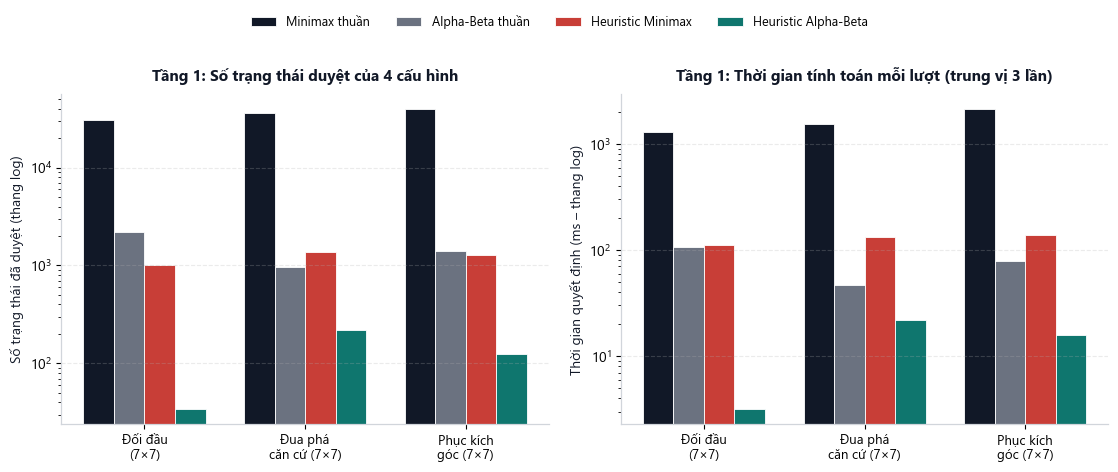

In [4]:
# Ve bieu do doi sanh 4 cau hinh tren Tang 1 voi chu giai ngang phia tren (khong de cot)
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.7), facecolor='white')
algos = ['Minimax thuần', 'Alpha-Beta thuần', 'Heuristic Minimax', 'Heuristic Alpha-Beta']
colors = [COLOR_INK, COLOR_MUTED, COLOR_ALERT, COLOR_PRIMARY]
scens = list(df_tier1['Kịch bản'].unique())
short_labels = ['Đối đầu\n(7×7)', 'Đua phá\ncăn cứ (7×7)', 'Phục kích\ngóc (7×7)']
x = np.arange(len(scens))
width = 0.19

handles = []
for idx, (algo, color) in enumerate(zip(algos, colors)):
    sub = df_tier1[df_tier1['Cấu hình thuật toán'] == algo]
    offset = (idx - 1.5) * width
    b0 = axes[0].bar(x + offset, sub['Số trạng thái duyệt'], width, label=algo, color=color, edgecolor='white', linewidth=0.6)
    axes[1].bar(x + offset, sub['Thời gian trung vị (ms)'], width, label=algo, color=color, edgecolor='white', linewidth=0.6)
    handles.append(b0)

axes[0].set_yscale('log')
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels, fontsize=9.5)
axes[0].set_ylabel('Số trạng thái đã duyệt (thang log)', fontsize=10, color=COLOR_INK)
axes[0].set_title('Tầng 1: Số trạng thái duyệt của 4 cấu hình', fontsize=11.2, fontweight='bold', color=COLOR_INK, pad=10)
axes[0].grid(axis='y', alpha=0.25, linestyle='--')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_labels, fontsize=9.5)
axes[1].set_ylabel('Thời gian quyết định (ms – thang log)', fontsize=10, color=COLOR_INK)
axes[1].set_title('Tầng 1: Thời gian tính toán mỗi lượt (trung vị 3 lần)', fontsize=11.2, fontweight='bold', color=COLOR_INK, pad=10)
axes[1].grid(axis='y', alpha=0.25, linestyle='--')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.legend(handles, algos, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=9.2)
fig.tight_layout(rect=[0, 0, 1, 0.93], pad=1.5)
fig.savefig(figure_dir / 'task2_four_algo_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## Phần 3 (Yêu cầu 2.2 — Tầng 2): Đấu Trường Đầy Đủ Máu (`9×9` & `11×11`) Theo Độ Sâu $d \in \{2, 3, 4\}$

Đo hiệu năng thời gian thực của `Heuristic Minimax` và `Heuristic Alpha-Beta` (+ Move Ordering + Transposition Table) trên hai đấu trường đầy đủ máu (`Tank=6`, `Base=9`, `Wall=3`), đồng thời kiểm chứng hai thuật toán cho ra đúng cùng giá trị lượng giá tại mọi độ sâu.

,Bản đồ,Độ sâu d,Thuật toán,Nước đi chọn,Số trạng thái duyệt,Nhánh cắt tỉa,Trúng TT,Thời gian trung vị (ms)
0,Đấu trường Cổ điển (9x9),2,Heuristic Minimax,BẮN,31,0,0,2.48
1,Đấu trường Cổ điển (9x9),2,Heuristic Alpha-Beta,BẮN,15,4,0,1.45
2,Đấu trường Cổ điển (9x9),3,Heuristic Minimax,BẮN,166,0,0,16.59
3,Đấu trường Cổ điển (9x9),3,Heuristic Alpha-Beta,BẮN,46,8,0,7.42
4,Đấu trường Cổ điển (9x9),4,Heuristic Minimax,BẮN,895,0,0,98.23
5,Đấu trường Cổ điển (9x9),4,Heuristic Alpha-Beta,BẮN,94,34,5,11.03
6,Công thành Pháo đài (11x11),2,Heuristic Minimax,LÊN,43,0,0,7.31
7,Công thành Pháo đài (11x11),2,Heuristic Alpha-Beta,LÊN,23,4,0,3.14
8,Công thành Pháo đài (11x11),3,Heuristic Minimax,TRÁI,253,0,0,44.72
9,Công thành Pháo đài (11x11),3,Heuristic Alpha-Beta,TRÁI,93,16,1,11.97


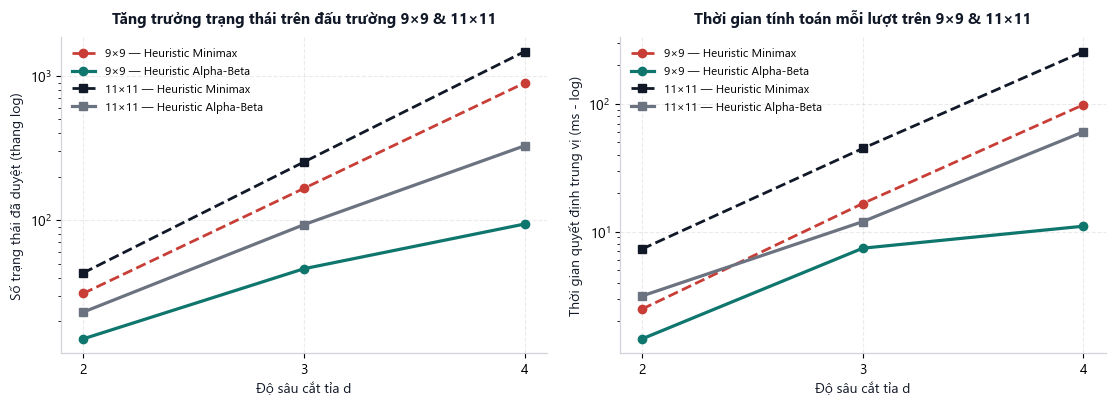

In [5]:
# Chay doi sanh Tang 2 tren 9x9 va 11x11 voi d = 2, 3, 4 va xuat bieu do
tier2_rows = []
for key in ('classic_9x9', 'fortress_11x11'):
    scen = get_scenario(key)
    s0 = scen.builder()
    for d in (2, 3, 4):
        hm = HeuristicMinimaxAgent(max_depth=d, name='Heuristic Minimax')
        hab = HeuristicAlphaBetaAgent(max_depth=d, name='Heuristic Alpha-Beta')
        vals = []
        for ag in (hm, hab):
            times = []
            act = 'STAY'
            for _ in range(3):
                act = ag.safe_choose_action(s0)
                times.append(ag.last_metrics.elapsed_ms)
            m = ag.last_metrics
            vals.append(m.best_value)
            tier2_rows.append({
                'Bản đồ': scen.title,
                'Độ sâu d': d,
                'Thuật toán': ag.name,
                'Nước đi chọn': ACTION_LABELS_VI.get(act, act),
                'Số trạng thái duyệt': m.explored_states,
                'Nhánh cắt tỉa': m.pruned_branches,
                'Trúng TT': m.tt_hits,
                'Thời gian trung vị (ms)': round(median(times), 2),
            })
        assert abs(vals[0] - vals[1]) < 1e-6

df_tier2 = pd.DataFrame(tier2_rows)
display(df_tier2)

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.3), facecolor='white')
line_styles = {
    ('Đấu trường Cổ điển (9x9)', 'Heuristic Minimax'): (COLOR_ALERT, '--', 'o', 2.0),
    ('Đấu trường Cổ điển (9x9)', 'Heuristic Alpha-Beta'): (COLOR_PRIMARY, '-', 'o', 2.3),
    ('Công thành Pháo đài (11x11)', 'Heuristic Minimax'): (COLOR_INK, '--', 's', 2.0),
    ('Công thành Pháo đài (11x11)', 'Heuristic Alpha-Beta'): (COLOR_MUTED, '-', 's', 2.3),
}
for (m_name, algo), grp in df_tier2.groupby(['Bản đồ', 'Thuật toán'], sort=False):
    color, ls, mk, lw = line_styles[(m_name, algo)]
    short = '9×9' if '9x9' in m_name else '11×11'
    lbl = f'{short} — {algo}'
    axes[0].plot(grp['Độ sâu d'], grp['Số trạng thái duyệt'], color=color, linestyle=ls, marker=mk, linewidth=lw, label=lbl)
    axes[1].plot(grp['Độ sâu d'], grp['Thời gian trung vị (ms)'], color=color, linestyle=ls, marker=mk, linewidth=lw, label=lbl)

for ax, ylabel, title in (
    (axes[0], 'Số trạng thái đã duyệt (thang log)', 'Tăng trưởng trạng thái trên đấu trường 9×9 & 11×11'),
    (axes[1], 'Thời gian quyết định trung vị (ms - log)', 'Thời gian tính toán mỗi lượt trên 9×9 & 11×11'),
):
    ax.set_yscale('log')
    ax.set_xticks([2, 3, 4])
    ax.set_xlabel('Độ sâu cắt tỉa d', fontsize=10, color=COLOR_INK)
    ax.set_ylabel(ylabel, fontsize=10, color=COLOR_INK)
    ax.set_title(title, fontsize=11.0, fontweight='bold', color=COLOR_INK, pad=10)
    ax.grid(alpha=0.25, linestyle='--')
    ax.legend(frameon=False, fontsize=8.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.tight_layout(pad=1.6)
fig.savefig(figure_dir / 'task2_tier2_9x9_vs_11x11.png', dpi=180, bbox_inches='tight')
plt.show()

## Phần 4 (Yêu cầu 2.3): Nạp Động Bot Nhóm Ngoài & Giải Đấu Đối Kháng Đầy Máu

Sử dụng `discover_external_agents()` nạp tự động cả 2 chuẩn bot nhóm ngoài (`OOP` kế thừa `BaseTankAgent` và `Dict Adapter` hàm `get_action(obs)`) rồi cho thi đấu trọn vẹn với `Heuristic Alpha-Beta (sâu 4)` trên bản đồ đầy đủ máu `Giao lộ Hỏa lực (9x9)`.

In [6]:
# Nap dong bot nhom ngoai va chay giai dau doi khang day mau tren Giao lo Hoa luc 9x9
ext_bots = discover_external_agents()
print(f'Phát hiện {len(ext_bots)} bot nhóm ngoài:', [b.name for b in ext_bots])

s0 = get_scenario('crossfire_9x9').builder()
matchups = [
    (HeuristicAlphaBetaAgent(max_depth=4, name='Heuristic Alpha-Beta (sâu 4)'),
     HeuristicMinimaxAgent(max_depth=2, name='Heuristic Minimax (sâu 2)')),
]
for bot in ext_bots:
    matchups.append((HeuristicAlphaBetaAgent(max_depth=4, name='Heuristic Alpha-Beta (sâu 4)'), bot))

match_rows = []
for p1, p2 in matchups:
    p1_times = []
    final_state = s0
    for snap in TankBattleEngine.iter_match(s0, p1, p2):
        final_state = snap.state
        if snap.player_id == PLAYER_MAX and snap.metrics is not None:
            p1_times.append(snap.metrics.elapsed_ms)
    w = final_state.winner()
    ket_qua = f'{p1.name} thắng' if w == PLAYER_MAX else (f'{p2.name} thắng' if w == PLAYER_MIN else 'Hòa (Hết lượt)')
    match_rows.append({
        'Phe MAX (Người chơi 1)': p1.name,
        'Phe MIN (Người chơi 2)': p2.name,
        'Số lượt đấu': final_state.ply,
        'Máu cuối (MAX Xe/CC vs MIN Xe/CC)': (
            f'{final_state.tanks[1].hp}/{final_state.bases[1].hp} vs '
            f'{final_state.tanks[2].hp}/{final_state.bases[2].hp}'
        ),
        'TG TB MAX (ms)': round(mean(p1_times), 2) if p1_times else 0.0,
        'Kết quả chung cuộc': ket_qua,
    })

df_matches = pd.DataFrame(match_rows)
df_matches

Phát hiện 2 bot nhóm ngoài: ['Bot ngoài: Săn căn cứ (Dict)', 'Bot ngoài: Xung kích (OOP)']


,Phe MAX (Người chơi 1),Phe MIN (Người chơi 2),Số lượt đấu,Máu cuối (MAX Xe/CC vs MIN Xe/CC),TG TB MAX (ms),Kết quả chung cuộc
0,Heuristic Alpha-Beta (sâu 4),Heuristic Minimax (sâu 2),119,6/9 vs 6/0,17.73,Heuristic Alpha-Beta (sâu 4) thắng
1,Heuristic Alpha-Beta (sâu 4),Bot ngoài: Săn căn cứ (Dict),15,1/9 vs 0/9,10.13,Heuristic Alpha-Beta (sâu 4) thắng
2,Heuristic Alpha-Beta (sâu 4),Bot ngoài: Xung kích (OOP),15,1/9 vs 0/9,9.89,Heuristic Alpha-Beta (sâu 4) thắng
